# 1. Implementación del Algoritmo Deutsch-Jozsa

- Este algoritmo sirve para determinar si una función booleana de $n$ bits es constante (devuelve siempre 0, o siempre 1, para cualquier entrada) o balanceada (devuelve 0 para la mitad de las entradas, y 1 para la otra mitad).

- Este algoritmo demuestra la ventaja del paralelismo cuántico, frente a una solución clásica.

- Un ordenador clásico requeriría $2^{n-1} + 1$ evaluaciones en el peor de los casos, mientras que el cuántico lo resuelve de un solo golpe (una única evaluación de la función).

## 1.1 Conexión con IBM Quantum

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [ ]:
!pip install -q qiskit-ibm-runtime
!pip install -q "python-dateutil<3.0,>=2.8.2"
# Ignorar el ERROR. Ocurre porque ibm_cloud_sdk_core necesita una versión más reciente de python, que la preinstalada por Colab.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibm-cloud-sdk-core 3.28.1 requires python_dateutil<3.1.0,>=3.0.0, bu

In [ ]:
import qiskit
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import userdata
ref1 = str(userdata.get('ref1'))

# Usamos la plataforma clásica de IBM Quantum, también podría ser ibm_cloud:
QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=ref1, overwrite=True)

# Probamos a inicializarlo y listar los simuladores/backends disponibles
service = QiskitRuntimeService()
print("¡Conectado con éxito!")
print(service.backends())

qiskit_runtime_service.__init__:WARNING:2026-11-01 14:00:53,980: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Santiago-server. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-01 14:00:53,990: Loading instance: Santiago-server, plan: open


¡Conectado con éxito!
[<IBMBackend('ibm_fez')>, <IBMBackend('ibm_kingston')>, <IBMBackend('ibm_marrakesh')>]


## 1.2 Diseñar el circuito cuántico

El circuito inicializará $n$ cubits de entrada al estado $\vert{}0\rangle$, y un cúbit auxiliar inicializado en $\vert{}1\rangle$.

Es decir, todos a 0, y el último cúbit a 1.

- Superposición Máxima: Aplicamos una puerta Hadamard ($H$) a todos los cúbits. Esto pone a los cúbits de entrada en una superposición equitativa de todas las $2^n$ combinaciones posibles de forma simultánea. Cada estado tiene la misma prob de aparecer.
- El Oráculo Cuántico ($U_f$): Aplica la función evaluando los qubits de entrada para modificar o no el qubit final (ancilla). Debido al phase kickback, y haber puesto el qubit ancilla en el estado 1 antes de la puerta H, esta modificación sobre la ancilla se traduce en un cambio de fase (un cambio de signo) en los estados de entrada, "dejando" el resultado de la función en las amplitudes de los qubits principales.
- Interferencia (Segunda capa de Hadamards): Se vuelve a aplicar una puerta $H$ a los cúbits de entrada. Este paso es crucial: debido a la interferencia cuántica, las rutas correspondientes a las respuestas incorrectas se cancelan destructivamente, mientras que la respuesta correcta amplifica su probabilidad.
- Medición: Se miden los cúbits de entrada. Si el resultado de la medición es exactamente $\vert{}00\dots0\rangle$, la función es constante. Si se obtiene cualquier otro estado diferente de cero, la función es balanceada.

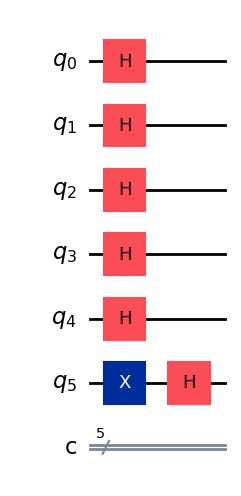

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()

# Creamos un circuito de prueba simple. Siempre se inicializan los qubits en el estado 0.
qc_1 = QuantumCircuit(6, 5)
qc_1.x(5)         # Aplicamos un not al último qubit, para tenerlo en el estado 1.
qc_1.h(range(6))  # Le aplicamos puertas H a todos
qc_1.draw(output = 'mpl')

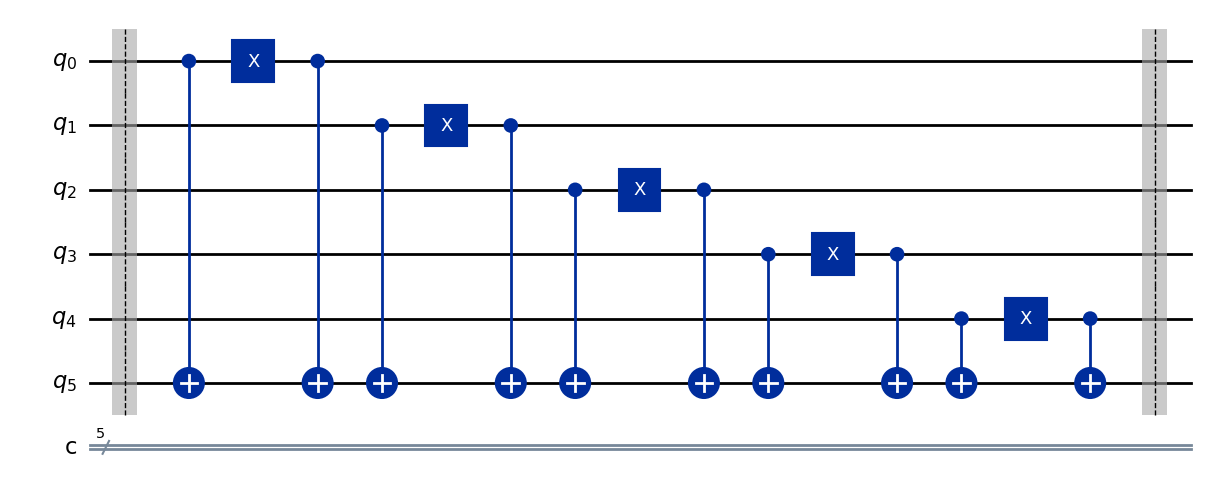

In [ ]:
# Función de ejemplo, para ver si es constante o balanceada. Podría ser cualquiera, en este caso, vamos a comprobar esta (es constante):

# 5 cúbits de entrada + 1 cúbit ancilla al final = 6 cúbits en total
qc_2 = QuantumCircuit(6,5)
qc_2.barrier(range(6))

# Iteramos solo sobre los cúbits de entrada (del 0 al 4)
for i in range(5):
  qc_2.cx(i, 5)  # CNOT. Control (lo que hay): el cúbit normal entrada i. Objetivo (lo que se modifica): el qubit ancilla final
  qc_2.x(i)      # Invertimos el cúbit de entrada
  qc_2.cx(i, 5)  # Aplicamos de nuevo el CNOT hacia la ancilla

qc_2.barrier(range(6))
qc_2.draw(output = 'mpl')

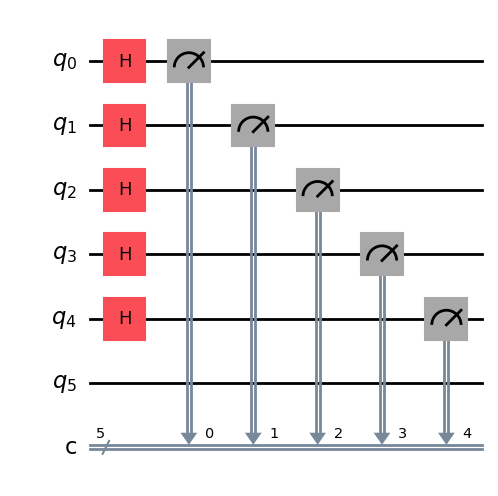

In [ ]:
qc_3 = QuantumCircuit(6,5)

qc_3.h(range(5))
qc_3.measure(range(5), range(5))

qc_3.draw(output = 'mpl')


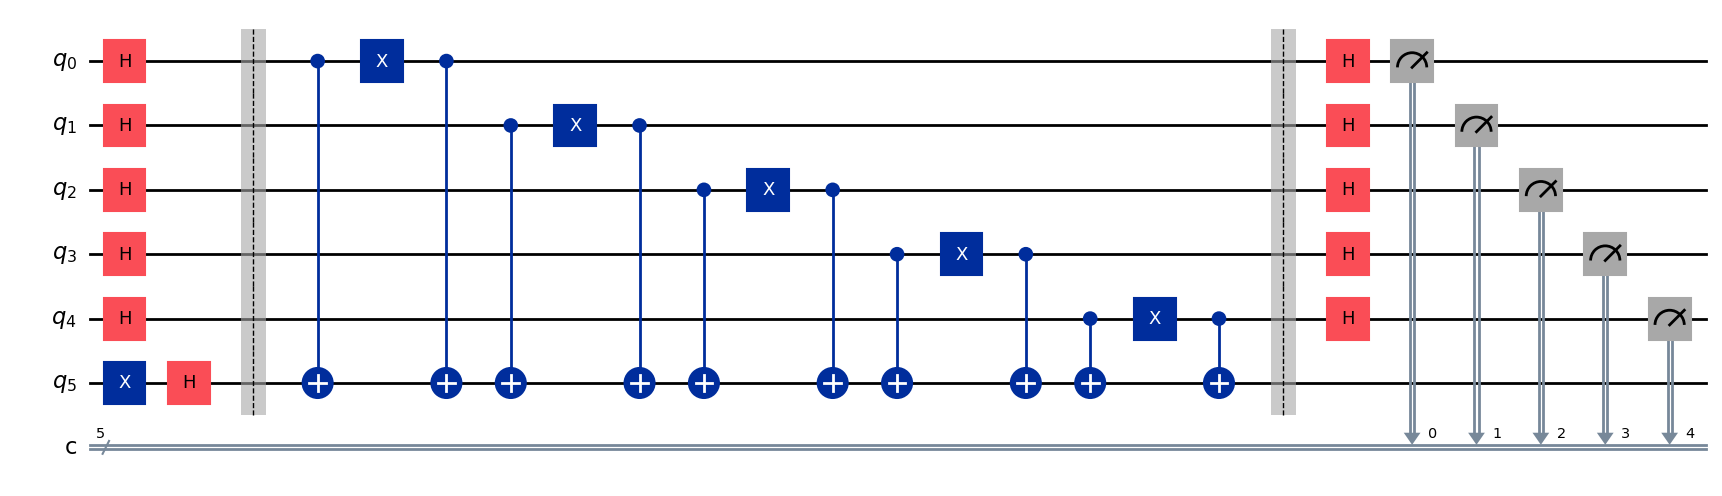

In [ ]:
qc_final = qc_1.compose(qc_2).compose(qc_3)
qc_final.draw(output = 'mpl')

Resultados de la medición: {'00000': 1}


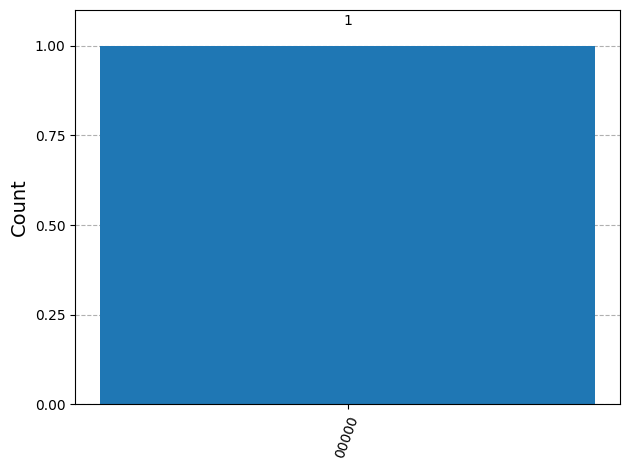

In [ ]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# 1. Inicializamos el simulador.
simulator = AerSimulator()

# 2. Ejecutamos el circuito directamente.
job = simulator.run(qc_final, shots=1)
result = job.result()
counts = result.get_counts()

# 3. Mostramos el resultado y el histograma.
print("Resultados de la medición:", counts)
plot_histogram(counts)

## Probando una función que No sea constante, sino balanceada

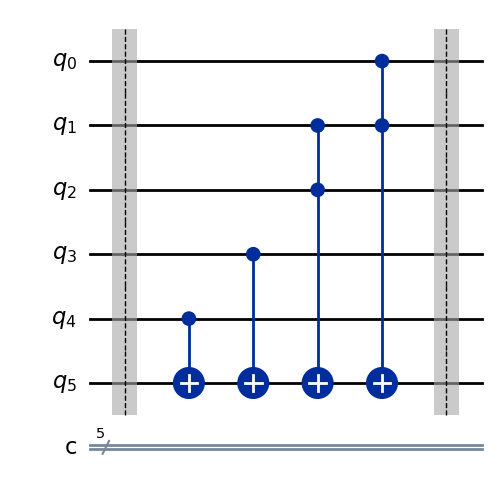

In [ ]:
from qiskit import QuantumCircuit

# 5 cúbits de entrada (0 a 4) + 1 cúbit ancilla (5)
qc_4 = QuantumCircuit(6, 5)
qc_4.barrier(range(6))

# Puertas CNOT simples desde algunos cúbits de entrada hacia la ancilla
qc_4.cx(4, 5) # si el q4 vale 1, invertimos el 5
qc_4.cx(3, 5) # si el q3 vale 1, invertimos el 5

# Puerta Toffoli (CCX) con dos controles y un objetivo (la ancilla). Si los dos valen 1, se invierte la ancilla, sino no.
qc_4.ccx(1, 2, 5)

# Puerta multicontrol (MCX) si queremos involucrar a más cúbits de entrada hacia la ancilla
# Por ejemplo, invierte la ancilla solo si los cúbits 0 y 1 están a 1
qc_4.mcx([0,1], 5)

qc_4.barrier(range(6))
qc_4.draw(output='mpl')

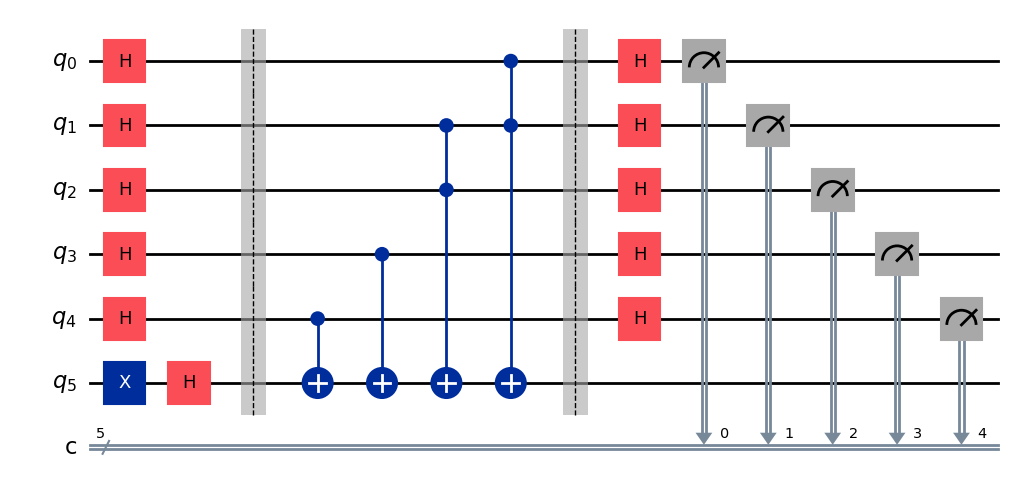

In [ ]:
qc_final2 = qc_1.compose(qc_4).compose(qc_3)

qc_final2.draw(output = 'mpl')

Resultados de la medición: {'11010': 1}


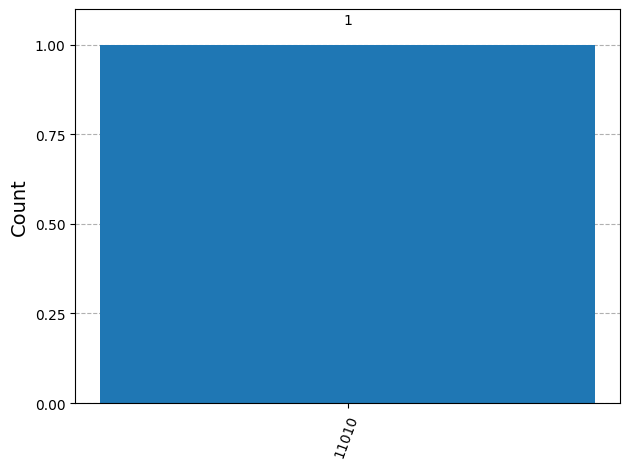

In [ ]:
simulator = AerSimulator()

job = simulator.run(qc_final2, shots=1)
result = job.result()
counts = result.get_counts()

print("Resultados de la medición:", counts)
plot_histogram(counts)

Como el resultado es != 00000, determinamos que es una función balanceada.